In [ ]:
!pip install xgboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import Lasso

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv("dataset_zone_1.csv")

print("Dataset Shape:", df.shape)

print("\nFirst Five Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

df = pd.read_csv("/content/dataset_zone_1.csv")

# Convert timestamp into useful features
df["ts"] = pd.to_datetime(df["ts"])
df["hour"] = df["ts"].dt.hour
df["day"] = df["ts"].dt.day
df["month"] = df["ts"].dt.month

# Remove timestamp and sensor columns with over 50% missing values
df = df.drop(columns=["ts"])
missing_percent = df.isnull().mean()
remove_cols = missing_percent[missing_percent > 0.50].index.tolist()
df = df.drop(columns=remove_cols)

# Fill remaining missing values using median
df = df.fillna(df.median())

# Separate features and target
X = df.drop(columns=["irrigation_duration_minutes", "liters_total"])
y = df["irrigation_duration_minutes"]

print("Removed columns:", remove_cols)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Remaining missing values:", df.isnull().sum().sum())
print("Rows with irrigation:", (y > 0).sum())
print("Dataset preparation completed!")

Removed columns: ['outside_temperature', 'inside_temperature', 'outside_humidity', 'inside_humidity', 'ec', 'soil_moisture']
Feature shape: (33259, 12)
Target shape: (33259,)
Remaining missing values: 0
Rows with irrigation: 718
Dataset preparation completed!


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import pandas as pd
import numpy as np

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, max_depth=4, learning_rate=0.1,
        random_state=42, n_jobs=-1
    ),
    "SVR": make_pipeline(
        StandardScaler(),
        SVR(kernel="rbf")
    ),
    "Stacking Ensemble": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=100, random_state=42, n_jobs=-1
            )),
            ("xgb", XGBRegressor(
                n_estimators=100, max_depth=4,
                learning_rate=0.1, random_state=42, n_jobs=-1
            )),
            ("svr", make_pipeline(StandardScaler(), SVR()))
        ],
        final_estimator=Ridge(),
        cv=3,
        n_jobs=-1
    )
}

# Train and evaluate
results = []

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("RMSE")
print("\nMODEL COMPARISON RESULTS")
display(results_df)

Training: Random Forest
Training: XGBoost
Training: SVR
Training: Stacking Ensemble

MODEL COMPARISON RESULTS


,Model,MAE,RMSE,R2 Score
3,Stacking Ensemble,0.137928,0.573956,0.821234
0,Random Forest,0.118903,0.602784,0.802825
1,XGBoost,0.313763,1.072284,0.376052
2,SVR,0.236984,1.351388,0.008966


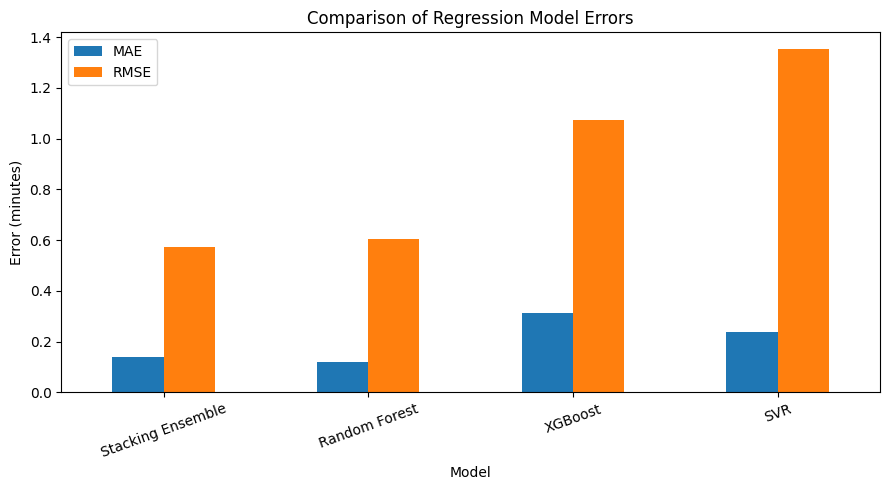

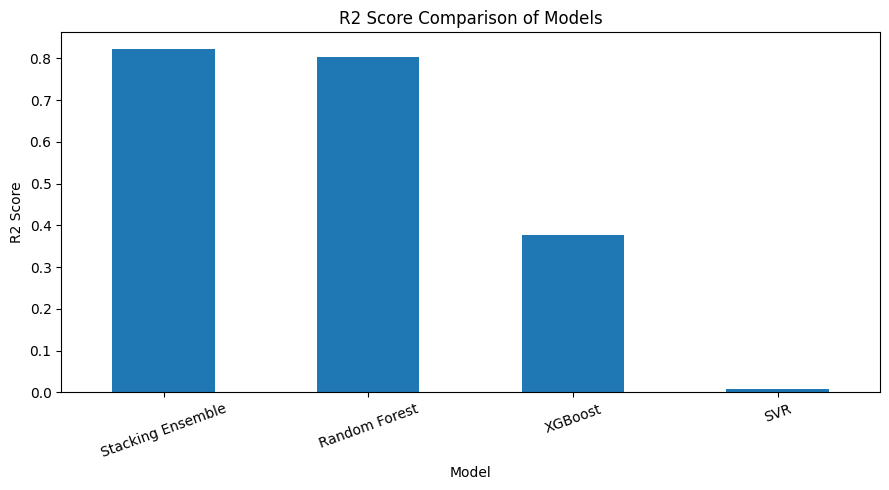

In [ ]:
import matplotlib.pyplot as plt

# Compare MAE and RMSE
results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("Comparison of Regression Model Errors")
plt.ylabel("Error (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("model_error_comparison.png", dpi=300)
plt.show()

# Compare R2 scores
results_df.set_index("Model")["R2 Score"].plot(
    kind="bar", figsize=(9, 5)
)
plt.title("R2 Score Comparison of Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("model_r2_comparison.png", dpi=300)
plt.show()

In [ ]:
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,
    r2_score, precision_score, recall_score, f1_score
)
import numpy as np
import pandas as pd

# Predict using the trained Stacking Ensemble
model = models["Stacking Ensemble"]
pred = model.predict(X_test)

# Evaluate rows where irrigation actually occurred
mask = y_test > 0

print("Actual irrigation rows in test set:", mask.sum())

if mask.sum() > 0:
    print("MAE on irrigation rows:",
          mean_absolute_error(y_test[mask], pred[mask]))
    print("RMSE on irrigation rows:",
          np.sqrt(mean_squared_error(y_test[mask], pred[mask])))
    print("R2 on irrigation rows:",
          r2_score(y_test[mask], pred[mask]))

# Check whether the model detects irrigation events
threshold = 0.5
actual_events = (y_test > 0).astype(int)
predicted_events = (pred > threshold).astype(int)

print("\nIrrigation Event Detection")
print("Precision:", precision_score(
    actual_events, predicted_events, zero_division=0))
print("Recall:", recall_score(
    actual_events, predicted_events, zero_division=0))
print("F1 Score:", f1_score(
    actual_events, predicted_events, zero_division=0))

Actual irrigation rows in test set: 141
MAE on irrigation rows: 2.4099654521777993
RMSE on irrigation rows: 3.2365512607003977
R2 on irrigation rows: -1.5446436406650963

Irrigation Event Detection
Precision: 0.39204545454545453
Recall: 0.9787234042553191
F1 Score: 0.5598377281947262


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Convert duration into an irrigation / no-irrigation label
y_train_event = (y_train > 0).astype(int)
y_test_event = (y_test > 0).astype(int)

# Train a classifier
classifier = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

classifier.fit(X_train, y_train_event)

# Predict irrigation events
event_pred = classifier.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test_event, event_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_event, event_pred,
    target_names=["No Irrigation", "Irrigation"],
    zero_division=0
))

Confusion Matrix:
[[6507    4]
 [  25  116]]

Classification Report:
               precision    recall  f1-score   support

No Irrigation       1.00      1.00      1.00      6511
   Irrigation       0.97      0.82      0.89       141

     accuracy                           1.00      6652
    macro avg       0.98      0.91      0.94      6652
 weighted avg       1.00      1.00      1.00      6652



In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Select rows with actual irrigation in training data
train_mask = y_train > 0

X_train_irrigation = X_train.loc[train_mask]
y_train_irrigation = y_train.loc[train_mask]

# Train duration prediction model
duration_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

duration_model.fit(X_train_irrigation, y_train_irrigation)

# Evaluate only actual irrigation events in test data
test_mask = y_test > 0

X_test_irrigation = X_test.loc[test_mask]
y_test_irrigation = y_test.loc[test_mask]

duration_pred = duration_model.predict(X_test_irrigation)

print("Duration Prediction Results")
print("MAE:", mean_absolute_error(y_test_irrigation, duration_pred))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_irrigation, duration_pred
)))
print("R2 Score:", r2_score(y_test_irrigation, duration_pred))

Duration Prediction Results
MAE: 1.0386879432624112
RMSE: 2.00590268143195
R2 Score: 0.022578901725275657


Baseline MAE: 1.4258883685484964
Random Forest MAE: 1.0386879432624112


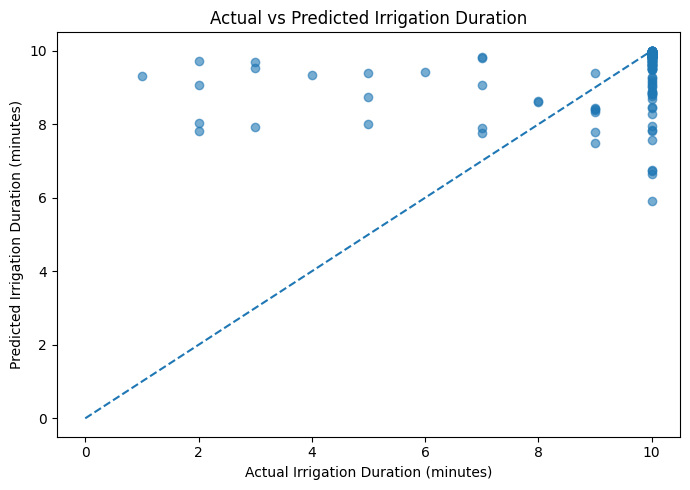

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_absolute_error

# Baseline: predict the average training irrigation duration
baseline_value = y_train[y_train > 0].mean()
baseline_pred = np.full(len(y_test_irrigation), baseline_value)

print("Baseline MAE:",
      mean_absolute_error(y_test_irrigation, baseline_pred))
print("Random Forest MAE:",
      mean_absolute_error(y_test_irrigation, duration_pred))

# Actual vs predicted graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test_irrigation, duration_pred, alpha=0.6)
plt.plot([0, 10], [0, 10], linestyle="--")
plt.xlabel("Actual Irrigation Duration (minutes)")
plt.ylabel("Predicted Irrigation Duration (minutes)")
plt.title("Actual vs Predicted Irrigation Duration")
plt.tight_layout()
plt.savefig("actual_vs_predicted_duration.png", dpi=300)
plt.show()

Training irrigation duration counts:
irrigation_duration_minutes
1      19
2       8
3       8
4      10
5       8
6      14
7      27
8      16
9      23
10    444
Name: count, dtype: int64


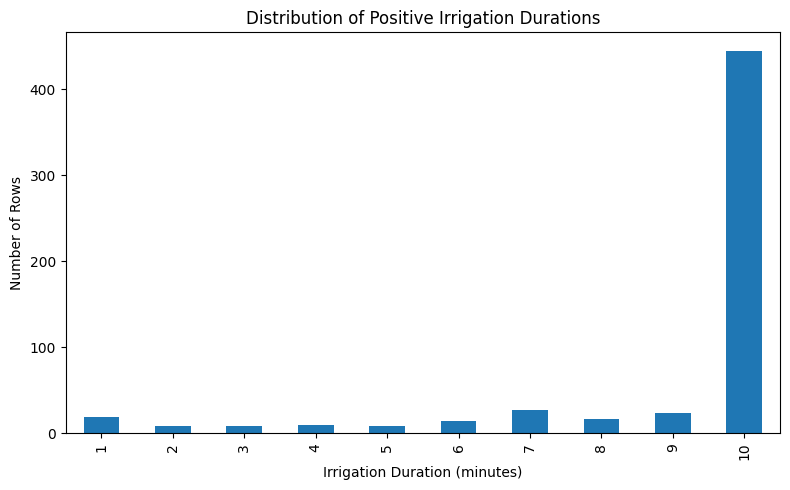

In [ ]:
import matplotlib.pyplot as plt

# Distribution of irrigation durations
print("Training irrigation duration counts:")
print(y_train[y_train > 0].value_counts().sort_index())

plt.figure(figsize=(8, 5))
y_train[y_train > 0].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Positive Irrigation Durations")
plt.xlabel("Irrigation Duration (minutes)")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.savefig("irrigation_duration_distribution.png", dpi=300)
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Count the frequency of each positive duration
counts = y_train_irrigation.value_counts()

# Give greater weight to less frequent durations
weights = y_train_irrigation.map(
    lambda value: len(y_train_irrigation) /
    (len(counts) * counts[value])
)

# Train improved model
improved_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

improved_model.fit(
    X_train_irrigation,
    y_train_irrigation,
    sample_weight=weights
)

# Predict on the same positive irrigation test rows
improved_pred = improved_model.predict(X_test_irrigation)

print("Improved Model Results")
print("MAE:", mean_absolute_error(y_test_irrigation, improved_pred))
print("RMSE:", np.sqrt(mean_squared_error(
    y_test_irrigation, improved_pred
)))
print("R2 Score:", r2_score(y_test_irrigation, improved_pred))

print("\nPrevious Random Forest MAE:",
      mean_absolute_error(y_test_irrigation, duration_pred))

Improved Model Results
MAE: 1.226796358185506
RMSE: 1.8975205575291723
R2 Score: 0.1253486498712989

Previous Random Forest MAE: 1.0386879432624112


In [ ]:
import joblib
import pandas as pd
import numpy as np

# Save both duration models
joblib.dump(duration_model, "previous_duration_model.pkl")
joblib.dump(improved_model, "improved_duration_model.pkl")

# Compare predictions on the same test rows
comparison = pd.DataFrame({
    "Actual Duration": y_test_irrigation.to_numpy(),
    "Previous RF Prediction": duration_pred,
    "Improved RF Prediction": improved_pred
})

display(comparison.head(15))

# Save comparison results
comparison.to_csv("duration_prediction_comparison.csv", index=False)

print("Both models and comparison results saved.")

,Actual Duration,Previous RF Prediction,Improved RF Prediction
0,10,9.860,9.741765
1,8,8.620,8.186436
2,10,9.535,9.541308
3,2,9.055,8.846404
4,7,7.900,7.919747
5,10,9.995,9.829562
6,10,9.655,9.321417
7,10,9.035,8.106036
8,10,8.895,9.247332
9,10,9.210,8.576572


Both models and comparison results saved.


combine two models


In [ ]:
import numpy as np
import pandas as pd

def predict_irrigation(input_data):
    # Predict whether irrigation is needed
    event = classifier.predict(input_data)[0]

    if event == 1:
        # Predict irrigation duration
        duration = duration_model.predict(input_data)[0]
        duration = np.clip(duration, 1, 10)
    else:
        duration = 0

    return {
        "Irrigation Required": "Yes" if event == 1 else "No",
        "Predicted Duration (minutes)": round(float(duration), 2)
    }

# Test using one row from the test dataset
sample = X_test.iloc[[0]]

result = predict_irrigation(sample)

print("Precision Irrigation Prediction")
print("------------------------------")
print("Input data:")
display(sample)
print("\nPrediction:")
print(result)

Precision Irrigation Prediction
------------------------------
Input data:


,weather_temp,weather_humidity,weather_rain,weather_pressure,weather_wind_speed,weather_radiation,soil_temperature_0-7cm,soil_temperature_7-18cm,ph,hour,day,month
19752,22.0,77.625,0.0,1010.8075,8.09,0.0,24.7475,29.285,7.0,4,26,6



Prediction:
{'Irrigation Required': 'No', 'Predicted Duration (minutes)': 0.0}


In [ ]:
import joblib

joblib.dump(classifier, "irrigation_classifier.pkl")
joblib.dump(duration_model, "irrigation_duration_model.pkl")
joblib.dump(improved_model, "improved_duration_model.pkl")

print("All models saved successfully!")

All models saved successfully!


In [ ]:
from google.colab import files

files.download("irrigation_classifier.pkl")
files.download("irrigation_duration_model.pkl")
files.download("improved_duration_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

final_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": 0.118903,
        "RMSE": 0.602784,
        "R2 Score": 0.802825
    },
    {
        "Model": "XGBoost",
        "MAE": 0.313763,
        "RMSE": 1.072284,
        "R2 Score": 0.376052
    },
    {
        "Model": "SVR",
        "MAE": 0.236984,
        "RMSE": 1.351388,
        "R2 Score": 0.008966
    },
    {
        "Model": "Stacking Ensemble",
        "MAE": 0.137928,
        "RMSE": 0.573956,
        "R2 Score": 0.821234
    }
])

display(final_results)

final_results.to_csv("final_model_comparison.csv", index=False)

print("Final results table saved successfully!")

,Model,MAE,RMSE,R2 Score
0,Random Forest,0.118903,0.602784,0.802825
1,XGBoost,0.313763,1.072284,0.376052
2,SVR,0.236984,1.351388,0.008966
3,Stacking Ensemble,0.137928,0.573956,0.821234


Final results table saved successfully!


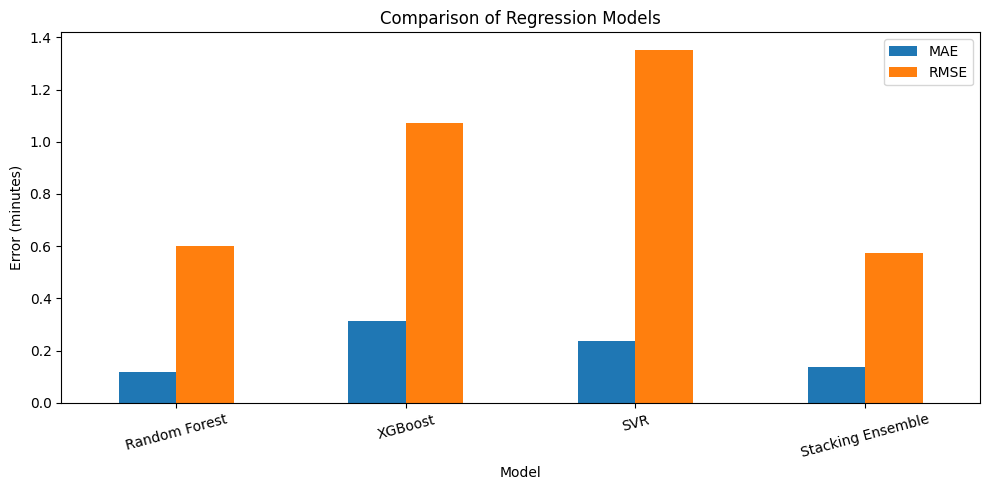

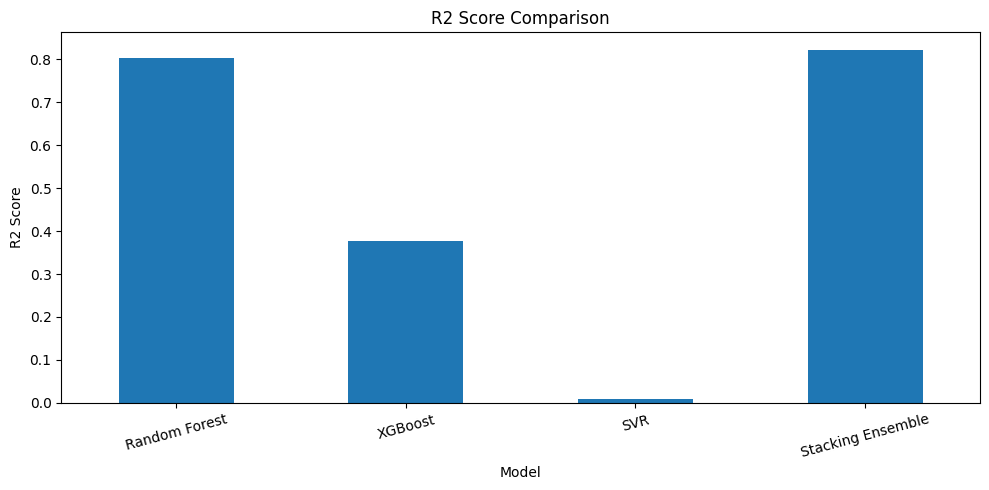

Final graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# MAE and RMSE comparison
final_results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Comparison of Regression Models")
plt.ylabel("Error (minutes)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("final_model_error_comparison.png", dpi=300)
plt.show()

# R2 score comparison
final_results.set_index("Model")["R2 Score"].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("final_model_r2_comparison.png", dpi=300)
plt.show()

print("Final graphs saved successfully!")

In [ ]:
from google.colab import files

files.download("final_model_error_comparison.png")
files.download("final_model_r2_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression, RFE
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Split the existing prepared dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Three feature techniques
techniques = {
    "SelectKBest": SelectKBest(
        score_func=mutual_info_regression, k=6
    ),
    "RFE": RFE(
        estimator=RandomForestRegressor(
            n_estimators=50, random_state=42, n_jobs=-1
        ),
        n_features_to_select=6
    ),
    "PCA": PCA(n_components=0.95)
}

# Models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100, max_depth=4,
        learning_rate=0.1, random_state=42, n_jobs=-1
    ),
    "SVR": SVR(),
    "Stacking Ensemble": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(
                n_estimators=100, random_state=42, n_jobs=-1
            )),
            ("xgb", XGBRegressor(
                n_estimators=100, max_depth=4,
                learning_rate=0.1, random_state=42, n_jobs=-1
            )),
            ("svr", SVR())
        ],
        final_estimator=Ridge(),
        cv=3
    )
}

# Train and compare
results = []

for technique_name, technique in techniques.items():
    for model_name, model in models.items():

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("feature_selection", clone(technique)),
            ("model", clone(model))
        ])

        pipeline.fit(X_train, y_train)
        predictions = pipeline.predict(X_test)

        results.append({
            "Feature Technique": technique_name,
            "Model": model_name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            ),
            "R2 Score": r2_score(y_test, predictions)
        })

comparison_df = pd.DataFrame(results).sort_values("RMSE")

print("APPROACH B: FEATURE TECHNIQUE COMPARISON")
display(comparison_df.round(4))

comparison_df.to_csv(
    "approach_b_feature_comparison.csv", index=False
)

print("Comparison completed and CSV saved.")


APPROACH B: FEATURE TECHNIQUE COMPARISON


,Feature Technique,Model,MAE,RMSE,R2 Score
3,SelectKBest,Stacking Ensemble,0.1087,0.5356,0.8443
7,RFE,Stacking Ensemble,0.1600,0.6453,0.7740
4,RFE,Random Forest,0.1384,0.6762,0.7519
11,PCA,Stacking Ensemble,0.2199,0.7703,0.6780
0,SelectKBest,Random Forest,0.1646,0.7846,0.6660
8,PCA,Random Forest,0.1796,0.8081,0.6456
5,RFE,XGBoost,0.3153,1.0649,0.3846
1,SelectKBest,XGBoost,0.3346,1.1191,0.3204
9,PCA,XGBoost,0.3406,1.1666,0.2614
10,PCA,SVR,0.2412,1.3548,0.0040


Comparison completed and CSV saved.
